# 02 — Preprocessing & Feature Engineering (Bebas *Data Leakage*)

**Modul Inti:** [`src/preprocessing.py`](../src/preprocessing.py)  
**Skrip CLI:** [`src/02_preprocessing.py`](../src/02_preprocessing.py)

Notebook ini menjalankan dan memverifikasi seluruh tahapan *preprocessing* sebelum pemodelan `Baseline KNN` (`E0`–`E1`) dan `DIFW-KNN` (`E2`–`E5`):
1. Pembersihan deterministik pra-split (*drop* `duration`, lestarikan `"unknown"`, mapping `y -> {0, 1}`).
2. *Stratified Train-Test Split* 80:20 (`random_state=42`) -> `36.168` train / `9.043` test.
3. Rekayasa fitur `pdays` berbasis *training-only* ($M_{\text{pos, train}}$) menghasilkan **16 fitur domain** (`6` numerik + `10` kategorikal/biner).
4. Fitting `BaselineEuclideanPreprocessor` dan `MixedTypePreprocessor` HANYA pada *training set*.
5. *Unit tests* properti metrik jarak *Mixed-Type* & perbandingan skala jarak.

## 1. Pembersihan Deterministik Pra-Split

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.edgecolor': '#CCCCCC',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
    'axes.titleweight': 'bold',
})

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    DEFAULT_RANDOM_STATE,
    DEFAULT_TEST_SIZE,
    DOMAIN_CATEGORICAL_COLS,
    DOMAIN_FEATURE_COLS,
    DOMAIN_NUMERIC_COLS,
    BaselineEuclideanPreprocessor,
    DomainFeatureEngineer,
    MixedTypeEncoded,
    MixedTypePreprocessor,
    clean_deterministic,
    load_raw_dataset,
    stratified_split_data,
)

raw_df = load_raw_dataset(PROJECT_ROOT / 'data' / 'bank-full.csv')
X_clean, y_clean = clean_deterministic(raw_df)

print(f'Raw shape          : {raw_df.shape}')
print(f'Cleaned X shape    : {X_clean.shape} (kolom duration dihapus)')
print(f"Apakah 'duration' masih ada? {'duration' in X_clean.columns}")
print(f'Distribusi y (0/1) : {y_clean.value_counts().to_dict()}')
print(f"Jumlah 'unknown' dipertahankan pada poutcome: {(X_clean['poutcome'] == 'unknown').sum():,}")

Raw shape          : (45211, 17)
Cleaned X shape    : (45211, 15) (kolom duration dihapus)
Apakah 'duration' masih ada? False
Distribusi y (0/1) : {0: 39922, 1: 5289}
Jumlah 'unknown' dipertahankan pada poutcome: 36,959


## 2. *Stratified Train-Test Split* (80:20) & Penyimpanan Split Bersih

,subset,n_rows,n_no,n_yes,pct_yes
0,Full (Cleaned),45211,39922,5289,11.6985
1,Train Split (80%),36168,31937,4231,11.6982
2,Test Split (20%),9043,7985,1058,11.6997


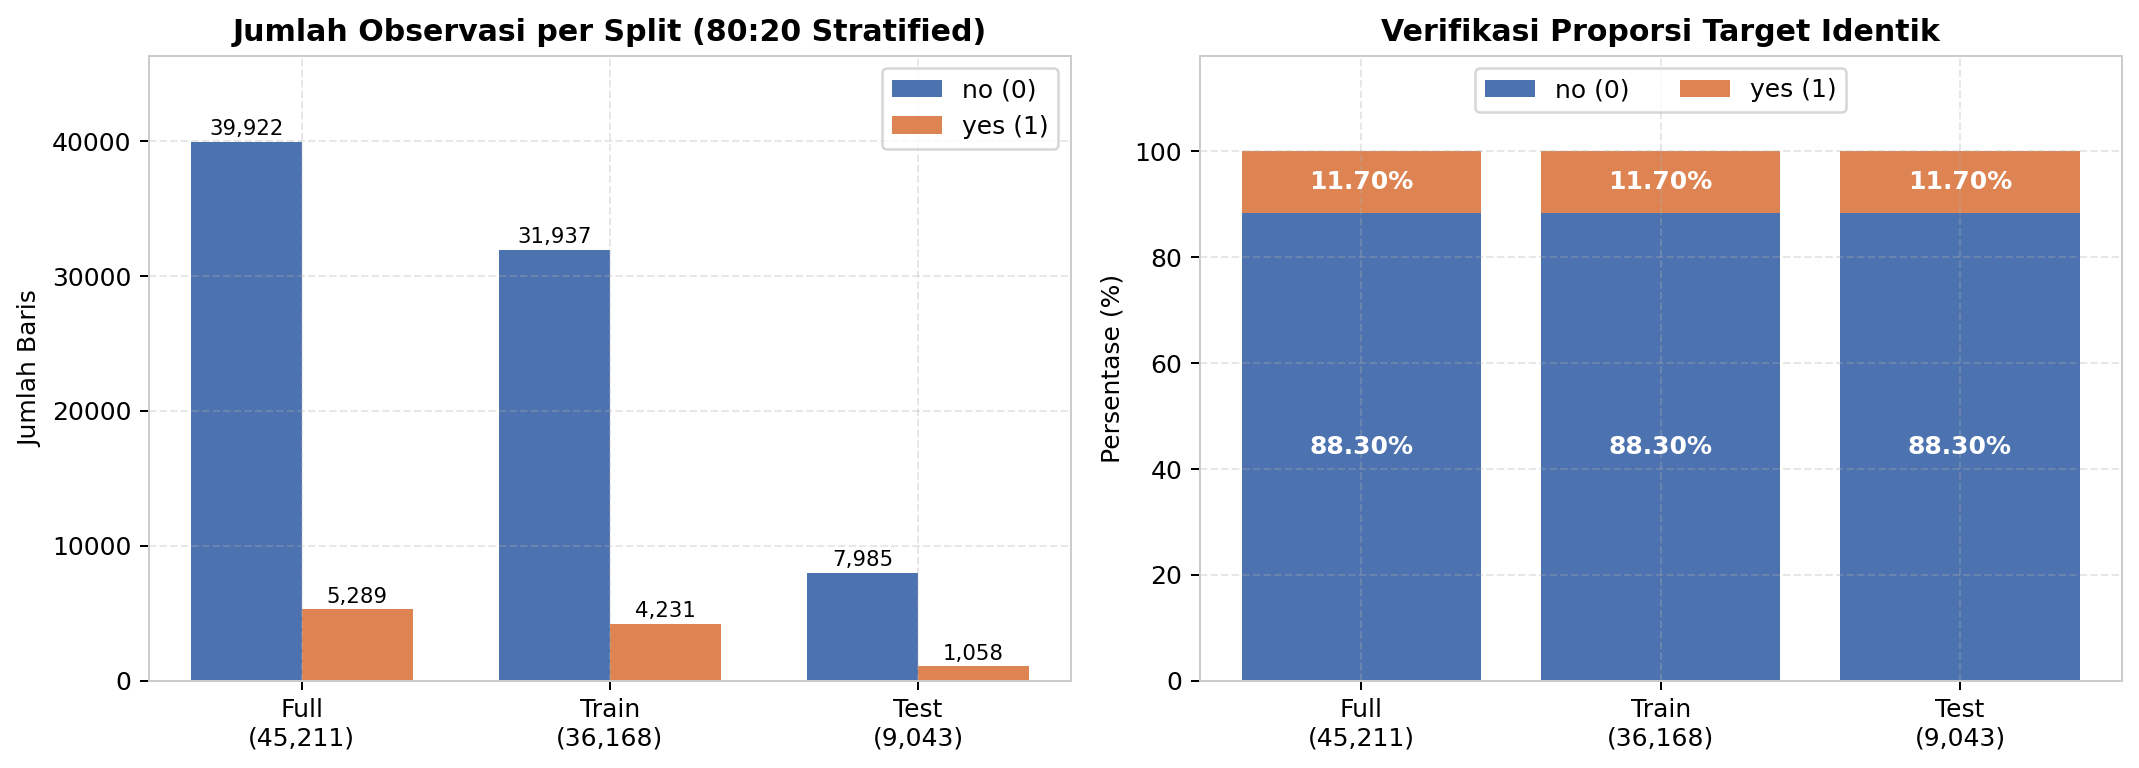

In [2]:
X_train_raw, X_test_raw, y_train, y_test = stratified_split_data(
    X_clean, y_clean, test_size=DEFAULT_TEST_SIZE, random_state=DEFAULT_RANDOM_STATE
)

processed_dir = PROJECT_ROOT / 'data' / 'processed'
processed_dir.mkdir(parents=True, exist_ok=True)
X_train_raw.assign(y=y_train).to_csv(processed_dir / 'train_split.csv', index=False)
X_test_raw.assign(y=y_test).to_csv(processed_dir / 'test_split.csv', index=False)

split_tbl = pd.DataFrame([
    {'subset': 'Full (Cleaned)', 'n_rows': len(X_clean), 'n_no': int((y_clean == 0).sum()), 'n_yes': int((y_clean == 1).sum()), 'pct_yes': round(100*y_clean.mean(), 4)},
    {'subset': 'Train Split (80%)', 'n_rows': len(X_train_raw), 'n_no': int((y_train == 0).sum()), 'n_yes': int((y_train == 1).sum()), 'pct_yes': round(100*y_train.mean(), 4)},
    {'subset': 'Test Split (20%)', 'n_rows': len(X_test_raw), 'n_no': int((y_test == 0).sum()), 'n_yes': int((y_test == 1).sum()), 'pct_yes': round(100*y_test.mean(), 4)},
])
display(split_tbl)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
labels_s = [f'Full\n({len(y_clean):,})', f'Train\n({len(y_train):,})', f'Test\n({len(y_test):,})']
x_pos = np.arange(len(labels_s))
b1 = axes[0].bar(x_pos - 0.18, split_tbl['n_no'], width=0.36, label='no (0)', color='#4C72B0')
b2 = axes[0].bar(x_pos + 0.18, split_tbl['n_yes'], width=0.36, label='yes (1)', color='#DD8452')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(labels_s)
axes[0].set_title('Jumlah Observasi per Split (80:20 Stratified)')
axes[0].set_ylabel('Jumlah Baris')
axes[0].set_ylim(0, split_tbl['n_no'].max() * 1.16)
axes[0].legend()
for bars in (b1, b2):
    for bar in bars:
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500, f'{int(bar.get_height()):,}', ha='center', fontsize=8.5)

pct_y = split_tbl['pct_yes'].to_numpy()
pct_n = 100.0 - pct_y
axes[1].bar(labels_s, pct_n, label='no (0)', color='#4C72B0')
axes[1].bar(labels_s, pct_y, bottom=pct_n, label='yes (1)', color='#DD8452')
axes[1].set_title('Verifikasi Proporsi Target Identik')
axes[1].set_ylabel('Persentase (%)')
axes[1].set_ylim(0, 118)
axes[1].legend(loc='upper center', ncol=2)
for idx, py in enumerate(pct_y):
    axes[1].text(idx, 100 - py/2, f'{py:.2f}%', ha='center', va='center', color='white', fontweight='bold')
    axes[1].text(idx, (100 - py)/2, f'{100-py:.2f}%', ha='center', va='center', color='white', fontweight='bold')
fig.tight_layout()
plt.show()

## 3. Rekayasa Fitur `pdays` Berbasis *Training-Only* ($M_{\text{pos, train}}$)

Untuk memisahkan status kontak historis dari kedekatan waktu (*recency*) tanpa membocorkan informasi dari data uji:
$$\text{previously\_contacted} = \mathbb{I}(\text{pdays} > -1), \qquad \text{pdays\_recency} = \begin{cases} \dfrac{1}{1 + \text{pdays} / M_{\text{pos, train}}}, & \text{pdays} > -1 \\ 0, & \text{pdays} = -1 \end{cases}$$
di mana $M_{\text{pos, train}} = \text{median}(\text{pdays} \mid \text{pdays} > -1)$ dihitung **hanya dari *training set***.

M_pos_train (median pdays > -1 pada training) = 195.0 hari
Total fitur domain = 16 (6 numerik + 10 kategorikal/biner)
Fitur numerik    : ['age', 'balance', 'day', 'campaign', 'previous', 'pdays_recency']
Fitur kategorikal: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'previously_contacted']


,subset,n_contacted,min_pos,median_pos,max_pos
0,Train,6584,0.1829,0.5000,0.9949
1,Test,1673,0.1888,0.5052,0.9949


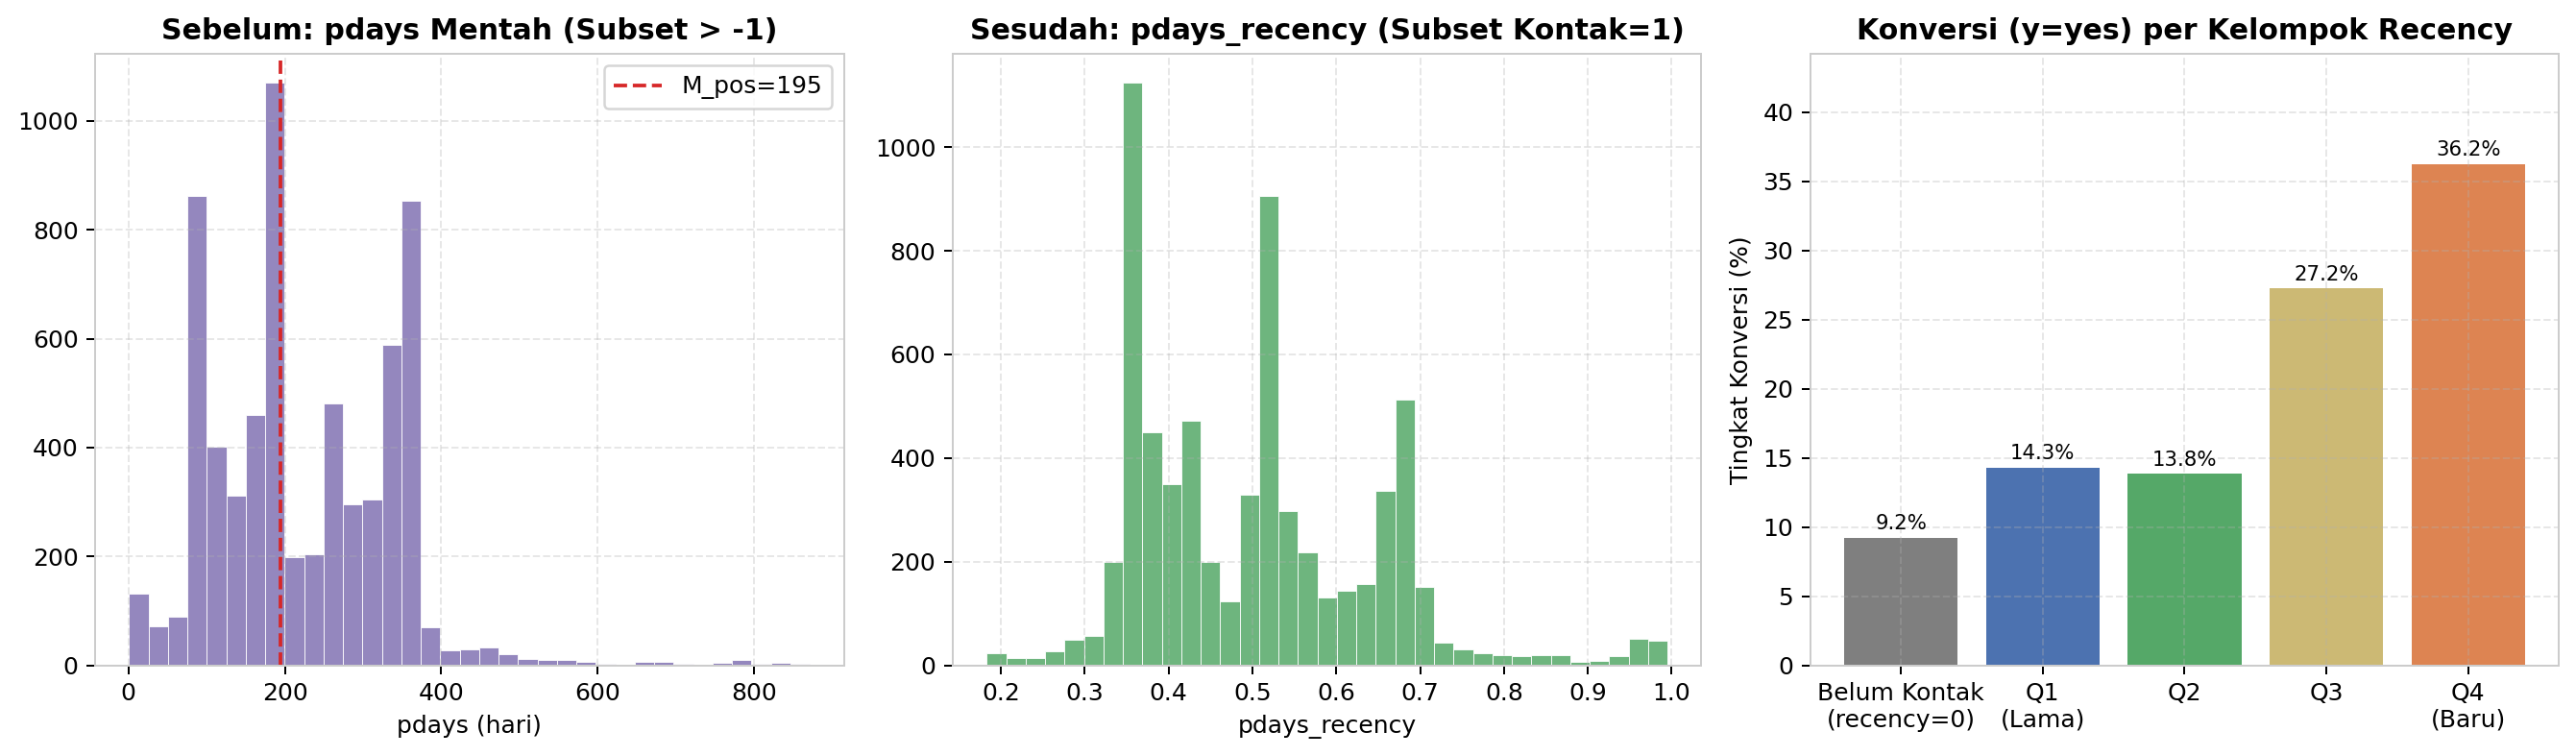

In [3]:
eng = DomainFeatureEngineer()
X_train_dom = eng.fit_transform(X_train_raw)
X_test_dom = eng.transform(X_test_raw)

print(f'M_pos_train (median pdays > -1 pada training) = {eng.pdays_median_pos_} hari')
print(f'Total fitur domain = {len(DOMAIN_FEATURE_COLS)} ({len(DOMAIN_NUMERIC_COLS)} numerik + {len(DOMAIN_CATEGORICAL_COLS)} kategorikal/biner)')
print('Fitur numerik    :', DOMAIN_NUMERIC_COLS)
print('Fitur kategorikal:', DOMAIN_CATEGORICAL_COLS)

rec_train = X_train_dom.loc[X_train_dom['previously_contacted'] == '1', 'pdays_recency']
rec_test = X_test_dom.loc[X_test_dom['previously_contacted'] == '1', 'pdays_recency']
display(pd.DataFrame([
    {'subset': 'Train', 'n_contacted': len(rec_train), 'min_pos': round(float(rec_train.min()), 4), 'median_pos': round(float(rec_train.median()), 4), 'max_pos': round(float(rec_train.max()), 4)},
    {'subset': 'Test', 'n_contacted': len(rec_test), 'min_pos': round(float(rec_test.min()), 4), 'median_pos': round(float(rec_test.median()), 4), 'max_pos': round(float(rec_test.max()), 4)},
]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].hist(X_train_raw.loc[X_train_raw['pdays'] > -1, 'pdays'], bins=35, color='#8172B3', alpha=0.85, edgecolor='white', linewidth=0.4)
axes[0].axvline(eng.pdays_median_pos_, color='#D62728', linestyle='--', label=f'M_pos={eng.pdays_median_pos_:.0f}')
axes[0].set_title('Sebelum: pdays Mentah (Subset > -1)')
axes[0].set_xlabel('pdays (hari)')
axes[0].legend()

axes[1].hist(rec_train, bins=35, color='#55A868', alpha=0.85, edgecolor='white', linewidth=0.4)
axes[1].set_title('Sesudah: pdays_recency (Subset Kontak=1)')
axes[1].set_xlabel('pdays_recency')

rec_df = pd.DataFrame({'prev': X_train_dom['previously_contacted'], 'rec': X_train_dom['pdays_recency'], 'y': y_train.to_numpy()})
not_c = rec_df[rec_df['prev'] == '0']
yes_c = rec_df[rec_df['prev'] == '1'].copy()
yes_c['q_bin'] = pd.qcut(yes_c['rec'], q=4, labels=['Q1 (Lama)', 'Q2', 'Q3', 'Q4 (Baru)'])
rates = [100.0 * not_c['y'].mean()] + [100.0 * yes_c.loc[yes_c['q_bin'] == q, 'y'].mean() for q in ['Q1 (Lama)', 'Q2', 'Q3', 'Q4 (Baru)']]
lbls = ['Belum Kontak\n(recency=0)', 'Q1\n(Lama)', 'Q2', 'Q3', 'Q4\n(Baru)']
bars_r = axes[2].bar(lbls, rates, color=['#7F7F7F', '#4C72B0', '#55A868', '#CCB974', '#DD8452'])
axes[2].set_title('Konversi (y=yes) per Kelompok Recency')
axes[2].set_ylabel('Tingkat Konversi (%)')
axes[2].set_ylim(0, max(rates) * 1.22)
for bar, val in zip(bars_r, rates):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.6, f'{val:.1f}%', ha='center', fontsize=8.5)
fig.tight_layout()
plt.show()

## 4. Fit Dua Jalur Preprocessor (*Training-Only*) & Audit Kategori *Unseen*

- **Jalur Baseline (`BaselineEuclideanPreprocessor`):** `StandardScaler` + `OneHotEncoder(handle_unknown='ignore', sparse_output=False)` untuk eksperimen `E0`–`E1`.
- **Jalur DIFW-KNN (`MixedTypePreprocessor`):** Menghitung kuantil $Q_{05,j}$, $Q_{95,j}$, dan $R_j = Q_{95,j} - Q_{05,j}$ pada 6 fitur numerik serta kamus kategori untuk 10 fitur kategorikal/biner.

In [4]:
euc_prep = BaselineEuclideanPreprocessor()
X_train_euc = euc_prep.fit_transform(X_train_raw)
X_test_euc = euc_prep.transform(X_test_raw)

mixed_prep = MixedTypePreprocessor()
X_train_enc = mixed_prep.fit_transform(X_train_raw)
X_test_enc = mixed_prep.transform(X_test_raw)

print(f'Baseline Euclidean -> X_train={X_train_euc.shape}, X_test={X_test_euc.shape}')
print(f'Mixed-Type         -> numeric={X_train_enc.numeric.shape}, categorical={X_train_enc.categorical.shape}')
display(mixed_prep.get_numeric_params_table())

unseen_rows = []
for col in DOMAIN_CATEGORICAL_COLS:
    tr_cats = set(X_train_dom[col].astype(str).unique())
    te_cats = set(X_test_dom[col].astype(str).unique())
    unseen = sorted(te_cats - tr_cats)
    unseen_rows.append({'feature': col, 'n_train_cat': len(tr_cats), 'n_test_cat': len(te_cats), 'n_unseen_in_test': len(unseen)})
display(pd.DataFrame(unseen_rows))

Baseline Euclidean -> X_train=(36168, 52), X_test=(9043, 52)
Mixed-Type         -> numeric=(36168, 6), categorical=(36168, 10)


,feature,q05_train,q95_train,range_q95_q05
0,age,27.0,59.000000,32.000000
1,balance,-171.0,5779.650000,5950.650000
2,day,3.0,29.000000,26.000000
3,campaign,1.0,8.000000,7.000000
4,previous,0.0,3.000000,3.000000
5,pdays_recency,0.0,0.568513,0.568513


,feature,n_train_cat,n_test_cat,n_unseen_in_test
0,job,12,12,0
1,marital,3,3,0
2,education,4,4,0
3,default,2,2,0
4,housing,2,2,0
5,loan,2,2,0
6,contact,3,3,0
7,month,12,12,0
8,poutcome,4,4,0
9,previously_contacted,2,2,0


## 5. *Unit Tests* Properti Metrik Jarak *Mixed-Type* & Perbandingan Skala Jarak

Memvalidasi bahwa fungsi jarak per-fitur $d_j(x, z) \in [0, 1]$ dan jarak berbobot $D_w(x, z) = \sum_j w_j d_j(x, z)$ memenuhi properti formal (*self-distance* $= 0$, simetri, batas $[0,1]$, tanpa `NaN/Inf`) serta membandingkan efek *outlier* pada skala jarak `StandardScaler` vs `Mixed-Type`.

,unit_check,status,value
0,Finite check (no NaN/Inf),PASS,"euc=True, mix=True"
1,"Self-distance d_j(x, x) = 0",PASS,0.0e+00
2,"Symmetry d_j(x, z) = d_j(z, x)",PASS,0.0e+00
3,"Distance bounds [0, 1]",PASS,"[0.0000, 1.0000]"
4,Batched vs exact weighted distance,PASS,1.1e-16


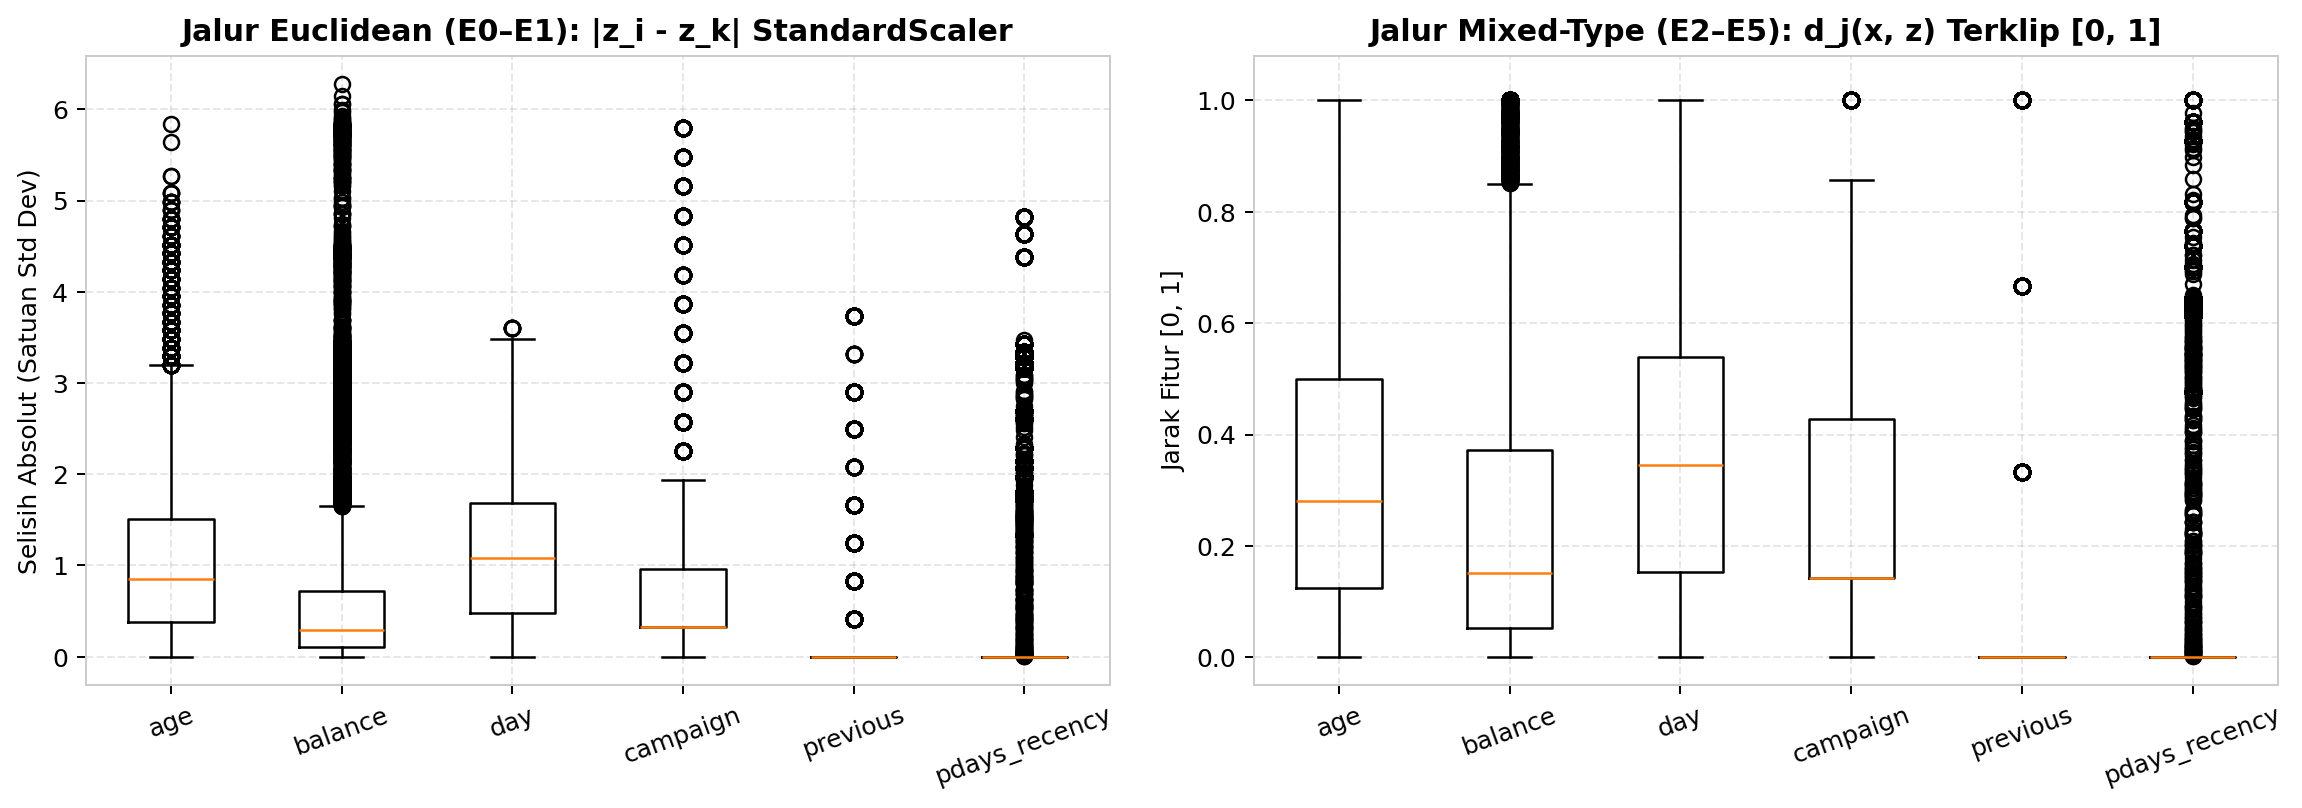

In [5]:
rng = np.random.default_rng(DEFAULT_RANDOM_STATE)
idx_a = rng.choice(X_train_enc.n_samples, size=200, replace=False)
idx_b = rng.choice(X_test_enc.n_samples, size=200, replace=False)
sub_a = MixedTypeEncoded(X_train_enc.numeric[idx_a], X_train_enc.categorical[idx_a], X_train_enc.feature_names)
sub_b = MixedTypeEncoded(X_test_enc.numeric[idx_b], X_test_enc.categorical[idx_b], X_test_enc.feature_names)

d_aa = mixed_prep.compute_pairwise_feature_distances(sub_a, sub_a)
d_ab = mixed_prep.compute_pairwise_feature_distances(sub_a, sub_b)
d_ba = mixed_prep.compute_pairwise_feature_distances(sub_b, sub_a)

euc_finite = bool(np.isfinite(X_train_euc).all() and np.isfinite(X_test_euc).all())
mix_finite = bool(np.isfinite(X_train_enc.numeric).all() and np.isfinite(X_test_enc.numeric).all())
diag_max = float(np.max(np.abs(np.diagonal(d_aa, axis1=0, axis2=1))))
sym_diff = float(np.max(np.abs(d_ab - np.transpose(d_ba, (1, 0, 2)))))
d_min, d_max = float(min(d_aa.min(), d_ab.min())), float(max(d_aa.max(), d_ab.max()))

u = np.full(len(DOMAIN_FEATURE_COLS), 1.0 / len(DOMAIN_FEATURE_COLS))
dw_exact = (d_ab * u[None, None, :]).sum(axis=2)
dw_batch = mixed_prep.compute_weighted_distance_matrix(sub_a, sub_b, weights=u, batch_size=64)
batch_diff = float(np.max(np.abs(dw_exact - dw_batch)))

assert euc_finite and mix_finite
assert diag_max == 0.0
assert sym_diff <= 1e-12
assert 0.0 <= d_min and d_max <= 1.0
assert batch_diff <= 1e-12

checks_tbl = pd.DataFrame([
    {'unit_check': 'Finite check (no NaN/Inf)', 'status': 'PASS', 'value': f'euc={euc_finite}, mix={mix_finite}'},
    {'unit_check': 'Self-distance d_j(x, x) = 0', 'status': 'PASS', 'value': f'{diag_max:.1e}'},
    {'unit_check': 'Symmetry d_j(x, z) = d_j(z, x)', 'status': 'PASS', 'value': f'{sym_diff:.1e}'},
    {'unit_check': 'Distance bounds [0, 1]', 'status': 'PASS', 'value': f'[{d_min:.4f}, {d_max:.4f}]'},
    {'unit_check': 'Batched vs exact weighted distance', 'status': 'PASS', 'value': f'{batch_diff:.1e}'},
])
display(checks_tbl)

iu = np.triu_indices(200, k=1)
euc_num_sub = X_train_euc[idx_a, :len(DOMAIN_NUMERIC_COLS)]
euc_diffs = [np.abs(euc_num_sub[:, j][iu[0]] - euc_num_sub[:, j][iu[1]]) for j in range(len(DOMAIN_NUMERIC_COLS))]
mix_diffs = [d_aa[:, :, j][iu[0], iu[1]] for j in range(len(DOMAIN_NUMERIC_COLS))]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].boxplot(euc_diffs, tick_labels=DOMAIN_NUMERIC_COLS, showfliers=True)
axes[0].set_title('Jalur Euclidean (E0–E1): |z_i - z_k| StandardScaler')
axes[0].set_ylabel('Selisih Absolut (Satuan Std Dev)')
axes[0].tick_params(axis='x', rotation=20)

axes[1].boxplot(mix_diffs, tick_labels=DOMAIN_NUMERIC_COLS, showfliers=True)
axes[1].set_title('Jalur Mixed-Type (E2–E5): d_j(x, z) Terklip [0, 1]')
axes[1].set_ylabel('Jarak Fitur [0, 1]')
axes[1].set_ylim(-0.05, 1.08)
axes[1].tick_params(axis='x', rotation=20)
fig.tight_layout()
plt.show()